<a href="https://colab.research.google.com/github/leon72305-source/public-infrastructure-sustainability-against-ev-growth/blob/main/infrastructure_sustainability_against_ev_growth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Public Charging Infrastructure vs EV Adoption Growth in the UK
#### Project : UFCEKP-30-3 Data Science and AI Individual Project

## Imports & Configuration

In [38]:
from google.colab import drive
drive.mount("/content/drive/")

import copy
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler  # Useful for linear/margin models if added
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,  # Key for imbalance / PR-AUC evaluation
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from xgboost import XGBClassifier
from sklearn.model_selection import TimeSeriesSplit

RANDOM_SEED = 42
folder_path = "/content/drive/MyDrive/DataSet/" # Sets up path for DataSet files to be extracted from

def section(title):
    print('\n' + '=' * 70)
    print(f'  {title}')
    print('=' * 70)

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


## Dataset Loading

In [39]:
section("DATASET LOADING & FILTERING")

missing_markers = ["[x]", "[z]", "[c]", "[low]", "[w]", ""] # Note marks on tables
ons_patterns = r"^[A-Z]\d{8}$" # Sets up filters for valid ONS code formats

def read_csv(file_name, rows_to_skip):# Removes commas and turns note marks to NaN values
  table = pd.read_csv(folder_path + file_name, skiprows=rows_to_skip, encoding="utf-8-sig",
                      thousands=",", na_values=missing_markers, keep_default_na=False, low_memory=False)
  table.columns = table.columns.str.strip() # Removes header spacing
  return table

# Loads csv files and skips header rows
df_chargers_raw = read_csv("evci9001.csv", 2)
df_vehicles_raw = read_csv("veh0142.csv", 4)

df_chargers = df_chargers_raw.rename(columns={"Local authority / region code": "ONS Code"}) # Renames ONS column format
df_chargers.columns = [re.sub(r"\s*\[Note\s*\d+\]", "", c).strip() for c in df_chargers.columns] # Removes note marks from header
df_chargers["ONS Code"] = df_chargers["ONS Code"].astype(str).str.strip()
df_chargers = df_chargers[df_chargers["ONS Code"].str.match(ons_patterns)].drop(columns="Local authority / region name") # Ensures only rows with valid ONS are used
charger_snapshot_columns = [col for col in df_chargers.columns if col != "ONS Code"]

# Ensures only rows with all totals to be used
only_total_rows = (
    (df_vehicles_raw["BodyType"] == "Total") &
    (df_vehicles_raw["Fuel"] == "Total") &
    (df_vehicles_raw["Keepership"] == "Total")
)
df_vehicles = df_vehicles_raw[only_total_rows].copy()
df_vehicles["ONS Code"] = df_vehicles["ONS Code"].astype(str).str.strip()
df_vehicles["ONS Geography"] = df_vehicles["ONS Geography"].astype(str).str.strip()
df_vehicles = df_vehicles[df_vehicles["ONS Code"].str.match(ons_patterns)]   # drops the [z] rows
vehicle_quarter_columns = [col for col in df_vehicles.columns if re.match(r"^\d{4}\s+Q[1-4]$", col)]

print(f"\nDataset is loaded and filtered with {len(df_chargers)} charger rows and {len(df_vehicles)} vehicle rows")


  DATASET LOADING & FILTERING

Dataset is loaded and filtered with 433 charger rows and 405 vehicle rows


## Handling ONS Code Changes and Mergers

In [40]:
section("ONS MERGER HANDLING")

# Remove abolished county rows to prevent double-counting
abolished_counties = {"E10000006", "E10000021", "E10000023", "E10000027"}
df_chargers = df_chargers[~df_chargers["ONS Code"].isin(abolished_counties)]

# Remap E07 districts to its updated E06 authority ONS codes
ons_merger_map = {
    # Cumbria to Cumberland (E06000063) & Westmorland and Furness (E06000064) [Apr 2023]
    "E07000026": "E06000063", "E07000028": "E06000063", "E07000029": "E06000063",
    "E07000027": "E06000064", "E07000030": "E06000064", "E07000031": "E06000064",

    # North Yorkshire to North Yorkshire UA (E06000065) [Apr 2023]
    "E07000163": "E06000065", "E07000164": "E06000065", "E07000165": "E06000065",
    "E07000166": "E06000065", "E07000167": "E06000065", "E07000168": "E06000065",
    "E07000169": "E06000065",

    # Northamptonshire to North (E06000061) & West Northamptonshire (E06000062) [Apr 2021]
    "E07000150": "E06000061", "E07000152": "E06000061", "E07000153": "E06000061",
    "E07000156": "E06000061", "E07000151": "E06000062", "E07000154": "E06000062",
    "E07000155": "E06000062",

    # Somerset to Somerset UA (E06000066) [Apr 2023]
    "E07000187": "E06000066", "E07000188": "E06000066", "E07000246": "E06000066",
    "E07000189": "E06000066",
}
df_chargers["ONS Code"] = df_chargers["ONS Code"].replace(ons_merger_map) # Replaces old ONS codes based on updated mapping

# Combines duplicated rows, while ensuring missing quarters stays NaN than becoming 0
df_chargers = df_chargers.groupby("ONS Code", as_index=False)[charger_snapshot_columns].sum(min_count=1)

print(f"\nCharger data now covers {df_chargers['ONS Code'].nunique()} codes after the 2021 and 2023 mergers")


  ONS MERGER HANDLING

Charger data now covers 405 codes after the 2021 and 2023 mergers


## Temporal Alignment

In [41]:
section("TEMPORAL ALIGNMENT")

start_index = 2019 * 4 + 4  # 2019 Q4
end_index = 2026 * 4 + 2    # 2026 Q2

snapshot_month_quarters= {"Jan": 4, "Apr": 1, "Jul": 2, "Oct": 3} # Snapshots are taken 1st of every month

def charger_column_quarter(column_name): # Converts charger columns to quarters
  month, short_year = column_name.split("-") # Separates month and year values
  year = 2000 + int(short_year) - (1 if month == "Jan" else 0)   # January represents Q4 of previous year
  quarter = snapshot_month_quarters[month]
  return f"{year} Q{quarter}", year * 4 + quarter # Utilizes numerical indexing for future sorting

# Performs numerical indexing for vehicle table
def vehicle_column_quarter(column_name):
  year, quarter_text = column_name.split()
  quarter = int(quarter_text[1])
  return f"{year} Q{quarter}", int(year) * 4 + quarter

# Reshape wide tables to long tables
def melt_quarter(df, id_columns, quarter_columns, column_quarter, value_name):
  long_table = df.melt(id_vars=id_columns, value_vars=quarter_columns, var_name="Raw Column", value_name=value_name)
  quarter_info = long_table["Raw Column"].map(column_quarter) # Converts raw dates to quarters
  long_table["Quarter"] = quarter_info.str[0]
  long_table["Quarter Index"] = quarter_info.str[1]
  data_range = long_table["Quarter Index"].between(start_index, end_index) # Ensures only 2019 Q4 until 2026 Q2 quarters are used
  return long_table[data_range].drop(columns="Raw Column")

chargers_long = melt_quarter(df_chargers, ["ONS Code"], charger_snapshot_columns,
                             charger_column_quarter, "Total Chargers")
vehicles_long = melt_quarter(df_vehicles, ["ONS Code", "ONS Geography", "ONS Sort"], vehicle_quarter_columns,
                              vehicle_column_quarter, "Total EVs")

print("\n Dataset is temporally aligned from 2019 Q4 to 2026 Q2")


  TEMPORAL ALIGNMENT

 Dataset is temporally aligned from 2019 Q4 to 2026 Q2


## Dataset Merging and Sorting

In [42]:
section("DATASET MERGING AND SORTING")

# Ensures charger only contribute count while quarter labels comes from vehicle dataset
df_core = pd.merge(
    vehicles_long,
    chargers_long[["ONS Code", "Quarter Index", "Total Chargers"]],
    on=["ONS Code", "Quarter Index"],
    how="inner",              # Keeps only values in both datasets
    validate="one_to_one"     # Checks if ONS code quarter rows appears twice
)
# Checks if there are dropped rows after merge
codes_vehicles_only = vehicles_long["ONS Code"].nunique() - df_core["ONS Code"].nunique()
codes_chargers_only = chargers_long["ONS Code"].nunique() - df_core["ONS Code"].nunique()
print(f"Dropped codes: Vehicles: {codes_vehicles_only}, Chargers: {codes_chargers_only}")

# Enables chronological sorting for each geography
df_core = df_core.sort_values(["ONS Sort", "ONS Code", "Quarter Index"]).reset_index(drop=True)

# Sets up filters for ONS prefix
region_type_map = {
    "K02": "National", "K03": "National",
    "E92": "Country", "W92": "Country", "S92": "Country", "N92": "Country",
    "E12": "Region",
    "E10": "Upper Tier", "E11": "Upper Tier", "E13": "Upper Tier",
    "E06": "Local Authority", "E07": "Local Authority", "E08": "Local Authority", "E09": "Local Authority",
    "W06": "Local Authority", "S12": "Local Authority", "N09": "Local Authority",
}
df_core["Geography Type"] = df_core["ONS Code"].str[:3].map(region_type_map).fillna("Other") # Classes geography types based on region map

df_core = df_core[[
    "ONS Code", "ONS Geography", "Geography Type", "Quarter", "Quarter Index",
    "Total EVs", "Total Chargers"
]]
display(df_core[df_core["Geography Type"] == "Local Authority"].head(10))


  DATASET MERGING AND SORTING
Dropped codes: Vehicles: 0, Chargers: 0


,ONS Code,ONS Geography,Geography Type,Quarter,Quarter Index,Total EVs,Total Chargers
108,E06000047,County Durham,Local Authority,2019 Q4,8080,805.0,96.0
109,E06000047,County Durham,Local Authority,2020 Q1,8081,926.0,102.0
110,E06000047,County Durham,Local Authority,2020 Q2,8082,952.0,105.0
111,E06000047,County Durham,Local Authority,2020 Q3,8083,1116.0,106.0
112,E06000047,County Durham,Local Authority,2020 Q4,8084,1244.0,110.0
113,E06000047,County Durham,Local Authority,2021 Q1,8085,1363.0,121.0
114,E06000047,County Durham,Local Authority,2021 Q2,8086,1645.0,116.0
115,E06000047,County Durham,Local Authority,2021 Q3,8087,1963.0,124.0
116,E06000047,County Durham,Local Authority,2021 Q4,8088,2262.0,128.0
117,E06000047,County Durham,Local Authority,2022 Q1,8089,2600.0,149.0


In [43]:
section("DATASET ASSERTIONS")

count_columns = ["Total EVs", "Total Chargers"]
assert not df_core[count_columns].isna().any().any(), "Missing counts from raw files"
df_core[count_columns] = df_core[count_columns].astype("int64")

assert not df_core.duplicated(["ONS Code", "Quarter Index"]).any(), "Duplicate ONS code quarter rows"
assert (df_core.groupby("ONS Code").size() == 27).all(), "ONS code rows lack the full 27 quarters"
assert (df_core[df_core["Geography Type"] == "Local Authority"].groupby("Quarter Index")["Total Chargers"].sum() # Utilize charger totals in the UK against manual count
        .equals(df_core[df_core["ONS Code"] == "K02000001"].set_index("Quarter Index")["Total Chargers"])), "Charger totals do not match"
print("All test cases passed! df_core is ready")


  DATASET ASSERTIONS
All test cases passed! df_core is ready


## Exploratory Data Analysis


  EXPLORATORY DATA ANALYSIS


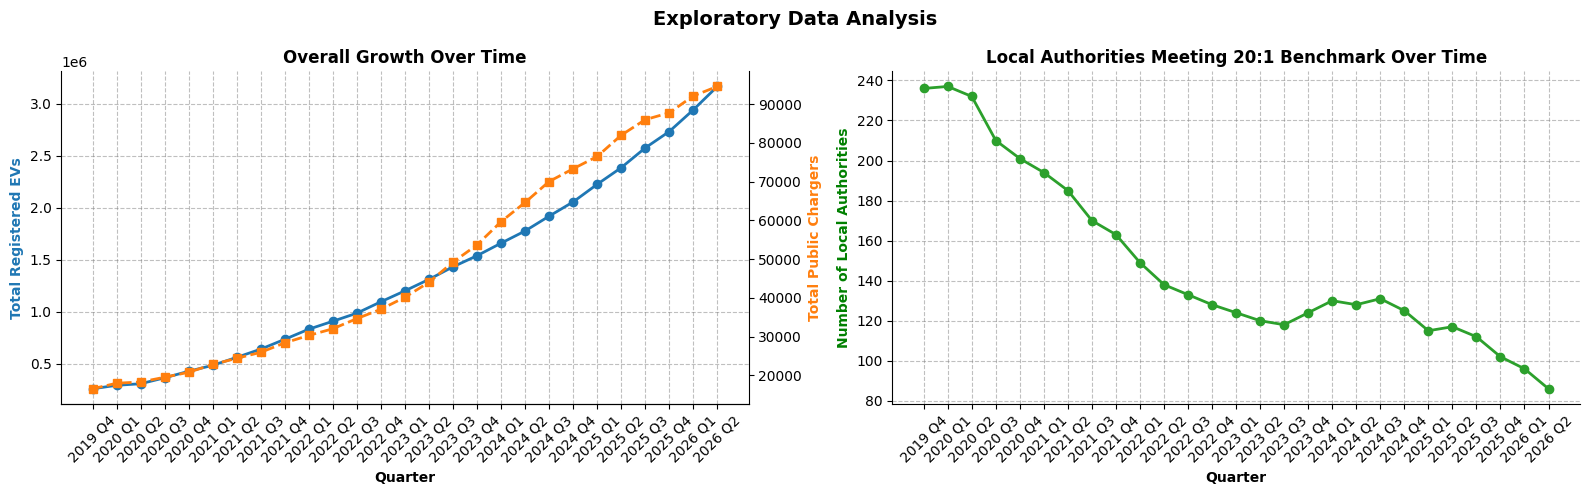

Highest Risk EV to Charger Ratios in Q2 2026


,ONS Code,ONS Geography,Total EVs,Total Chargers,EVs per Charger
6722,E06000040,Windsor and Maidenhead,267700,198,1352.0
6641,E06000039,Slough,52369,97,539.9
4157,E06000031,Peterborough,109387,220,497.2
917,E08000007,Stockport,100304,242,414.5
593,E06000050,Cheshire West and Chester,95299,287,332.1
8585,E06000025,South Gloucestershire,64152,318,201.7
6560,E06000042,Milton Keynes,150129,793,189.3
2402,E07000038,North East Derbyshire,3771,28,134.7
809,E08000002,Bury,9143,71,128.8
1970,E08000035,Leeds,96623,757,127.6


In [44]:
section("EXPLORATORY DATA ANALYSIS")
df_local = df_core[df_core["Geography Type"] == "Local Authority"].copy()
df_local["EV_Charger_Ratio"] = df_local["Total EVs"] / df_local["Total Chargers"].clip(lower=1) # Clipping chargers at 1 to prevent division by 0
df_local["Benchmark Ratio"] = df_local["EV_Charger_Ratio"] <= 20 # Sets 20:1 benchmark

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Exploratory Data Analysis', fontsize=14, fontweight='bold')

ax1 = axes[0]
quarterly_totals = df_local.groupby('Quarter')[['Total EVs', 'Total Chargers']].sum().reset_index()

ax1.plot(quarterly_totals['Quarter'], quarterly_totals['Total EVs'], label='Total EVs (Sum)', color='#1f77b4', marker='o', linewidth=2)
ax1.set_title('Overall Growth Over Time', fontweight='bold')
ax1.set_ylabel('Total Registered EVs', color='#1f77b4', fontweight='bold')
ax1.set_xlabel('Quarter', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
[ax1.spines[s].set_visible(False) for s in ['top', 'right']]

ax2 = ax1.twinx()
ax2.plot(quarterly_totals['Quarter'], quarterly_totals['Total Chargers'], label='Total Chargers (Sum)', color='#ff7f0e', marker='s', linewidth=2, linestyle='--')
ax2.set_ylabel('Total Public Chargers', color='#ff7f0e', fontweight='bold')
ax2.grid(False) # Prevent gridline clashing
[ax2.spines[s].set_visible(False) for s in ['top', 'left']]

ax3 = axes[1]
benchmark_counts = (
    df_local.groupby('Quarter')['Benchmark Ratio']
    .sum()
    .reindex(quarterly_totals['Quarter'], fill_value=0)
    .reset_index(name='Local Authorities Meeting 20:1')
)
ax3.plot(
    benchmark_counts['Quarter'],
    benchmark_counts['Local Authorities Meeting 20:1'],
    color='#2ca02c',
    marker='o',
    linewidth=2
)
ax3.set_title('Local Authorities Meeting 20:1 Benchmark Over Time', fontweight='bold')
ax3.set_ylabel('Number of Local Authorities', color='Green', fontweight='bold')
ax3.set_xlabel('Quarter', fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
[ax3.spines[s].set_visible(False) for s in ['top', 'right']]

ax1.grid(color='gray', linestyle='--', alpha=0.5)
ax3.grid(color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

df26_quarters = pd.DataFrame(df_local[df_local['Quarter'] == '2026 Q2']).copy()
df26_risk = (
    df26_quarters.sort_values('EV_Charger_Ratio', ascending=False) # Enables display of highest to lowest at-risk regions
    [['ONS Code', 'ONS Geography', 'Total EVs', 'Total Chargers', 'EV_Charger_Ratio']]
    .rename(columns={'EV_Charger_Ratio': 'EVs per Charger'})
    .head(10)
    .copy()
)
df26_risk['Total EVs'] = df26_risk['Total EVs'].round().astype(int)
df26_risk['Total Chargers'] = df26_risk['Total Chargers'].round().astype(int)
df26_risk['EVs per Charger'] = df26_risk['EVs per Charger'].round(1)

print("Highest Risk EV to Charger Ratios in Q2 2026")
display(df26_risk)

## Feature Engineering

In [45]:
section("FEATURE ENGINEERING")

lag_quarters = [1, 2, 4]
baseline_ratio = 20 # 20:1 Charger-to-EV baseline

df_features = (
    df_core[df_core["Geography Type"] == "Local Authority"] # Ensures only data from individual regions are used
    [["ONS Code", "ONS Geography", "Quarter", "Quarter Index", "Total EVs", "Total Chargers"]]
    .sort_values(["ONS Code", "Quarter Index"]).reset_index(drop=True) # Ensures ONS codes are grouped in quarterly order
)
df_features["EVs per Charger"] = df_features["Total EVs"] / df_features["Total Chargers"].clip(lower=1) # Calculates EVs per charger, clipping counts to 1 to prevent division by 0
df_features["Deficit Flag"] = (df_features["Total EVs"] > baseline_ratio * df_features["Total Chargers"]).astype(int)
df_features["Deficit Status"] = np.where(df_features["Deficit Flag"] == 1, "AT-RISK", "SAFE") # Groups flag results as 1 if AT-RISK, else SAFE

cols_to_lag = ["Total EVs", "Total Chargers", "EVs per Charger", "Deficit Flag"]
ons_to_lag = df_features.groupby("ONS Code") # Ensures lag features only utilize each ONS' own history
for column in cols_to_lag:
  for lag in lag_quarters:
    df_features[f"{column} Lag{lag}"] = ons_to_lag[column].shift(lag)

# Sets targets and lags by looking 1 quarter forward
df_features["Target Deficit Flag"] = ons_to_lag["Deficit Flag"].shift(-1)
next_evs = ons_to_lag["Total EVs"].shift(-1)
next_chargers = ons_to_lag["Total Chargers"].shift(-1)

# Calculates growth rate from current to next quarter
df_features["Target EV Growth"] = (next_evs - df_features["Total EVs"]) / df_features["Total EVs"].clip(lower=1)
df_features["Target Charger Growth"] = (next_chargers - df_features["Total Chargers"]) / df_features["Total Chargers"].clip(lower=1)

feature_columns = cols_to_lag + [f"{column} Lag{lag}" for column in cols_to_lag for lag in lag_quarters] # Creates columns for lag feature results
target_columns = ["Target Deficit Flag", "Target EV Growth", "Target Charger Growth"]

df_model = df_features.dropna(subset=feature_columns).copy() # Removes rows with incomplete lag histories for actual model training

# Counts rows from incomplete lag histories
print(f"Local Authorities: {df_features['ONS Code'].nunique()} | Dropped incomplete rows: "
      f"{len(df_features)} to {len(df_model)}")

def lag_table(ons_code, column, rows=12):
  columns_table = (
        ["ONS Code", "Quarter", column]
        + [f"{column} Lag{lag}" for lag in lag_quarters]
        + ["Deficit Flag", "Deficit Status"]
  )
  area_rows = df_features.loc[df_features["ONS Code"] == ons_code, columns_table] # Filters rows for selected ONS for display only
  area_name = df_features.loc[df_features["ONS Code"] == ons_code, "ONS Geography"].iloc[0] # Filters name of selected ONS
  print(f"\n{column} Lag features for {ons_code} ({area_name})")
  display(area_rows.head(rows))

selected_ons = df_features["ONS Code"].unique()[0] # Displays ONS code based on unique index order
lag_table(selected_ons, "Total Chargers")
lag_table(selected_ons, "Total EVs")


  FEATURE ENGINEERING
Local Authorities: 361 | Dropped incomplete rows: 9747 to 8303

Total Chargers Lag features for E06000001 (Hartlepool)


,ONS Code,Quarter,Total Chargers,Total Chargers Lag1,Total Chargers Lag2,Total Chargers Lag4,Deficit Flag,Deficit Status
0,E06000001,2019 Q4,5,NaN,NaN,NaN,0,SAFE
1,E06000001,2020 Q1,6,5.0,NaN,NaN,0,SAFE
2,E06000001,2020 Q2,6,6.0,5.0,NaN,0,SAFE
3,E06000001,2020 Q3,6,6.0,6.0,NaN,1,AT-RISK
4,E06000001,2020 Q4,8,6.0,6.0,5.0,0,SAFE
5,E06000001,2021 Q1,9,8.0,6.0,6.0,0,SAFE
6,E06000001,2021 Q2,10,9.0,8.0,6.0,0,SAFE
7,E06000001,2021 Q3,11,10.0,9.0,6.0,0,SAFE
8,E06000001,2021 Q4,13,11.0,10.0,8.0,1,AT-RISK
9,E06000001,2022 Q1,12,13.0,11.0,9.0,1,AT-RISK



Total EVs Lag features for E06000001 (Hartlepool)


,ONS Code,Quarter,Total EVs,Total EVs Lag1,Total EVs Lag2,Total EVs Lag4,Deficit Flag,Deficit Status
0,E06000001,2019 Q4,99,NaN,NaN,NaN,0,SAFE
1,E06000001,2020 Q1,108,99.0,NaN,NaN,0,SAFE
2,E06000001,2020 Q2,112,108.0,99.0,NaN,0,SAFE
3,E06000001,2020 Q3,128,112.0,108.0,NaN,1,AT-RISK
4,E06000001,2020 Q4,135,128.0,112.0,99.0,0,SAFE
5,E06000001,2021 Q1,149,135.0,128.0,108.0,0,SAFE
6,E06000001,2021 Q2,181,149.0,135.0,112.0,0,SAFE
7,E06000001,2021 Q3,215,181.0,149.0,128.0,0,SAFE
8,E06000001,2021 Q4,268,215.0,181.0,135.0,1,AT-RISK
9,E06000001,2022 Q1,320,268.0,215.0,149.0,1,AT-RISK


In [46]:
section("FEATURE ENGINEERING ASSERTIONS")

def ons_quarter_lookup(column, quarter_offset):
  index_values = df_features.set_index(["ONS Code", "Quarter Index"])[column] # Creates lookup table indexed by ONS code and quarter indexes
  lookup_keys = pd.MultiIndex.from_arrays([df_features["ONS Code"], df_features["Quarter Index"] + quarter_offset]) # Creates keys to lookup values of ONS at shifted quarter
  return index_values.reindex(lookup_keys).to_numpy() # Returns matched values as numpy values

for column in cols_to_lag:
  for lag in lag_quarters:
    # Ensures Lag values matches value of the quarter earlier for each ONS code
    assert np.allclose(df_features[f"{column} Lag{lag}"], ons_quarter_lookup(column, -lag), equal_nan=True), \
      f"{column} Lag{lag} does not match the value {lag} quarter earlier"

assert np.allclose(df_features["Target Deficit Flag"],
                   ons_quarter_lookup("Deficit Flag", 1),
                   equal_nan=True), "Target is not next quarter" # Ensures target is deficit flag from next quarter

assert not any(column in feature_columns for column in target_columns), "Target columns is used as an input" # Ensures no target variable is included in model inputs
assert df_features.groupby("ONS Code").head(1)["Total EVs Lag1"].isna().all(), "First quarter should have no Lag1" # Lag1 has no previous quarter
assert df_features.groupby("ONS Code").head(4)["Total EVs Lag4"].isna().all(), "First four quarters should have NaN Lag4" # Lag4 has no quarters a year earlier
assert (df_features.groupby("ONS Code").size() == df_features["Quarter Index"].nunique()).all(), "Unequal amount of quarters"

print("All test cases passed! all lag values are valid")


  FEATURE ENGINEERING ASSERTIONS
All test cases passed! all lag values are valid



  LAG FEATURES CORRELATION PLOTS


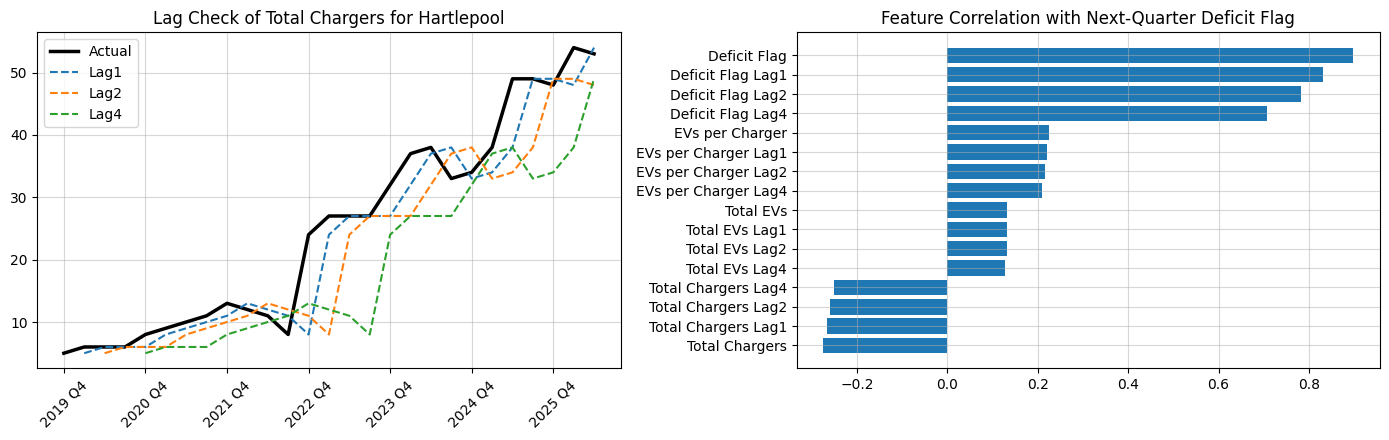

In [47]:
section("LAG FEATURES CORRELATION PLOTS")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

ons_area = df_features[df_features["ONS Code"] == selected_ons] # Extract specific rows for selected ONS code
axes[0].plot(ons_area["Quarter"], ons_area["Total Chargers"], label="Actual", linewidth=2.5, color="black")

for lag in lag_quarters:
  axes[0].plot(ons_area["Quarter"], ons_area[f"Total Chargers Lag{lag}"], label=f"Lag{lag}", linestyle="--") # Plots total chargers shifts of selected ONS
axes[0].set_xticks(range(0, len(ons_area), 4))
axes[0].set_xticklabels(ons_area["Quarter"].iloc[::4], rotation=45)
axes[0].set_title(f"Lag Check of Total Chargers for {ons_area['ONS Geography'].iloc[0]}")
axes[0].legend()

# Measures correlation between model features and next-quarter deficit risks
training_rows = df_model.dropna(subset=["Target Deficit Flag"]) # Creates new DataFrame with only rows with target variables
feature_correlation = training_rows[feature_columns].corrwith(training_rows["Target Deficit Flag"]).sort_values() # Calculate correlations between each model feature and next quarter deficit risk

axes[1].barh(feature_correlation.index, feature_correlation.values, color="tab:blue")
axes[1].set_title("Feature Correlation with Next-Quarter Deficit Flag")

for axis in axes:
    axis.grid(alpha=0.5)

plt.tight_layout()
plt.show()

## Splitting and Scaling

## Baselines and Model Training

## Held-Out Evaluation on Test Sets